**Human Movement Intelligence | Multimodal Movement Learning | Presented by: Reza Saadatyar (2026)**

**01 | NinaPro DB2 Source Pairing and Label Audit**

![Original S01 E1 recordings, source-level sensor pairing, corrected label audit and evidence exports](../../images/01_ninapro_pairing_and_label_audit.svg)

**Research question:** Does the original NinaPro DB2 exercise-one (E1) recording contain identifiable, row-aligned sEMG and acceleration measurements, usable corrected movement labels and traceable repetition boundaries?

**Original source:** [NinaPro DB2](https://ninapro.hevs.ch/instructions/DB2.html), participant S01, file `DB2_s1/S1_E1_A1.mat`. The participant archive is approximately **448.47 MiB**; its three MATLAB files represent the E1, E2 and E3 exercises.

**Observed S01 evidence:** **1,808,331 released sample rows** (approximately **904.17 s** on the published 2,000-Hz grid), **12 sEMG channels**, **36 accelerometer columns**, **18 corrected class codes (0–17)** and **205 contiguous corrected-label/repetition segments**.

**Notebook scope:** Inspect the source archive and MATLAB schema, verify paired row counts and finite values, characterise corrected labels and repetitions, plot an actual two-second source interval, and export source dictionaries for Notebook 02. The common 2,000-Hz release grid does **not** imply that the native accelerometers sampled at 2,000 Hz.

**Research boundary:** This is a descriptive source audit, not a movement classifier, independent synchronisation experiment or validation of real-time prosthesis control.

**00. Colab Repository Setup**

In [1]:
# ======================== 00. Colab Repository Setup =========================

# -------------------------- 1. Repository Checkout ---------------------------
from pathlib import Path
import subprocess

repo_url = "https://github.com/RezaSaadatyar/human-movement-intelligence.git"
repo_path = Path("/content") / repo_url.rsplit("/", 1)[-1].removesuffix(".git")
if not repo_path.exists():
    subprocess.run(["git", "clone", "-q", repo_url, str(repo_path)], check=True)

# ---------------------------- 2. Open Repository -----------------------------
%cd {repo_path}


/content/human-movement-intelligence


**01. Imports and Research Environment**

In [2]:
# =================== 01. Imports and Research Environment ====================

# ------------------------ 1. Study Environment Setup -------------------------
from python_modules.core.colab_setup import setup_colab
root = setup_colab("multimodal_movement_learning")

# ----------------- 2. Scientific Computing and Data Analysis -----------------
import numpy as np
import pandas as pd

# ------------------- 3. Visualisation and Notebook Display -------------------
import matplotlib.pyplot as plt
from IPython.display import display
from core.plot_style import plot_style, save_figure
from core.output_download import download_outputs_from_colab

plot_style(
    font_family="DejaVu Sans", title_size=12.5, title_weight="normal",
    label_size=11.5, label_weight="normal", tick_size=11,
    legend_size=10, figure_dpi=100, figure_size=(9, 4),
)

# ------------------------ 4. Study Research Utilities ------------------------
from ninapro_source import (
    RELEASED_RATE_HZ, ensure_subject_archive,
    list_mat_members, load_exercise, inspect_record, contiguous_segments,
)

# ---------------------- 5. Source and Output Locations -----------------------
study_dir = root / "multimodal_movement_learning"
output_dir = study_dir / "output"
processed_dir = root / "data" / "processed" / "ninapro_db2"
raw_dir = root / "data" / "raw" / "ninapro_db2"
output_dir.mkdir(parents=True, exist_ok=True)
processed_dir.mkdir(parents=True, exist_ok=True)
print("Research output directory:", output_dir)


Repository up to date.
Research output directory: /content/human-movement-intelligence/multimodal_movement_learning/output


**02. Acquire One Original Participant Archive**

The reader locates `DB2_s1.zip` under `data/raw/ninapro_db2/`; when the archive is already available there, it is reused. Otherwise, the official DB2 preprocessed ZIP is downloaded, checked for a valid archive and retained under its stable participant-specific filename. The observed S01 archive occupies **448.47 MiB** and contains three separate exercise MATLAB entries.

The E1 file is selected for paired hand-movement analysis. Acquisition is separate from the small `output/` research tables: an archive that remains available in the active environment is not downloaded again, but a new ephemeral Colab environment may need the source archive to be obtained again.

In [3]:
# =============== 02. Acquire One Original Participant Archive ================

NOTEBOOK_NUMBER = 1
PILOT_SUBJECT = 1
EXERCISE_ID = 1
DOWNLOAD_MISSING = True

source = ensure_subject_archive(
    raw_dir, PILOT_SUBJECT, download=DOWNLOAD_MISSING,
)
print("Subject source:", source.name)
print("Archive size (MiB):", round(source.stat().st_size / (1024**2), 2))
print("MATLAB entries:", list_mat_members(source))


Subject source: DB2_s1.zip
Archive size (MiB): 448.47
MATLAB entries: ['DB2_s1/S1_E1_A1.mat', 'DB2_s1/S1_E2_A1.mat', 'DB2_s1/S1_E3_A1.mat']


**03. Read Paired MATLAB Measurements**

Exercise E1 contains the source fields `emg`, `acc`, `restimulus` and `rerepetition`, together with the corresponding original annotation fields. The verified S01 arrays have **1,808,331 rows**, with `emg` shaped **(1,808,331, 12)** and `acc` shaped **(1,808,331, 36)**.

The sEMG measurements and the three-axis acceleration columns refer to the **same released sample rows**, not to signals paired by matching class labels after acquisition. The source inspection table records channel coverage, label identities, corrected repetitions and the nominal duration obtained from the released row grid.

In [4]:
# ==================== 03. Read Paired MATLAB Measurements ====================

record = load_exercise(source, PILOT_SUBJECT, exercise=EXERCISE_ID)
audit = pd.DataFrame([inspect_record(record)])
display(audit.T.rename(columns={0: "observed value"}))
print("EMG shape:", record.emg.shape, "| Acc shape:", record.acc.shape)
print("Released source-sample rate (Hz):", RELEASED_RATE_HZ)


,observed value
subject_id,S01
exercise_id,1
source_file,DB2_s1/S1_E1_A1.mat
samples,1808331
duration_s_nominal,904.1655
emg_channels,12
acc_columns,36
emg_finite_fraction,1.0
acc_finite_fraction,1.0
corrected_labels,"0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17"


EMG shape: (1808331, 12) | Acc shape: (1808331, 36)
Released source-sample rate (Hz): 2000.0


**04. Inspect Time Base and Source-Level Alignment**

Check that the sEMG rows, acceleration rows, corrected labels and repetition identifiers all have the same length. For S01 E1, **all four arrays contain 1,808,331 rows**, so a source row identifies a common stored position across the measured and annotation streams.

The recorded nominal duration is **904.1655 s** using the documented **2,000-Hz released grid**. The original accelerometers were acquired at approximately **148 Hz**, then represented on the common released time base. Consequently, successive stored acceleration rows are not independent native 2,000-Hz samples. Equal row counts establish **stored-array correspondence**, not an independent measurement of inter-device clock offset or native synchronisation precision.

In [5]:
# ============= 04. Inspect Time Base and Source-Level Alignment ==============

rows = len(record.emg)
alignment_summary = pd.DataFrame([{
    "subject_id": record.subject_id,
    "emg_rows": rows,
    "acc_rows": len(record.acc),
    "corrected_label_rows": len(record.restimulus),
    "repetition_rows": len(record.rerepetition),
    "nominal_duration_s": rows / RELEASED_RATE_HZ,
    "native_acc_sampling_hz_published": 148,
}])
assert alignment_summary[["emg_rows", "acc_rows", "corrected_label_rows", "repetition_rows"]].nunique(axis=1).eq(1).all()
display(alignment_summary)


,subject_id,emg_rows,acc_rows,corrected_label_rows,repetition_rows,nominal_duration_s,native_acc_sampling_hz_published
0,S01,1808331,1808331,1808331,1808331,904.1655,148


**05. Audit Corrected Labels and Repetitions**

The `restimulus` field provides the corrected prompted-movement labels used by this study. The observed S01 E1 codes are **0 (Rest)** and **1–17 (seventeen movement classes)**. Rest occupies **1,064,608 of 1,808,331 samples (58.87%)**; the remaining samples represent the non-rest movements.

The source segmentation identifies **205 contiguous label/repetition intervals**. Corrected repetition codes **0–6** occur, with each of the seventeen non-rest labels represented by **six contiguous movement segments** in this participant. `rerepetition` preserves repetition identity for source-based segmentation; it is not a predictive feature. These are observed *pilot-subject* properties, not guarantees that every other participant has identical eligibility or durations.

The corrected-boundary procedure described for the published data uses information from sEMG. Its annotation provenance must remain explicit when interpreting an eventual sEMG-versus-acceleration comparison.

In [6]:
# ================ 05. Audit Corrected Labels and Repetitions =================

labels, counts = np.unique(record.restimulus, return_counts=True)
label_dictionary = pd.DataFrame({
    "exercise_id": EXERCISE_ID,
    "label": labels.astype(int),
    "source_samples": counts.astype(int),
    "duration_s_nominal": counts / RELEASED_RATE_HZ,
})
segments = contiguous_segments(record.restimulus, record.rerepetition)
segment_frame = pd.DataFrame(segments, columns=[
    "start_sample", "end_sample", "label", "repetition_id",
])
segment_frame["duration_s"] = (segment_frame.end_sample - segment_frame.start_sample) / RELEASED_RATE_HZ
display(label_dictionary)
print("Corrected repetitions:", sorted(np.unique(record.rerepetition).tolist()))
print("Source label segments:", len(segment_frame))
display(segment_frame.groupby("label", as_index=False).agg(segments=("label", "size"),
    median_duration_s=("duration_s", "median")))


,exercise_id,label,source_samples,duration_s_nominal
0,1,0,1064608,532.3040
1,1,1,78701,39.3505
2,1,2,58979,29.4895
3,1,3,50985,25.4925
4,1,4,45065,22.5325
5,1,5,40125,20.0625
6,1,6,25557,12.7785
7,1,7,58155,29.0775
8,1,8,28238,14.1190
9,1,9,39903,19.9515


Corrected repetitions: [0, 1, 2, 3, 4, 5, 6]
Source label segments: 205


,label,segments,median_duration_s
0,0,103,5.22350
1,1,6,6.45850
2,2,6,4.78925
3,3,6,4.23500
4,4,6,3.90850
5,5,6,3.43825
6,6,6,2.17275
7,7,6,4.83150
8,8,6,2.39850
9,9,6,3.41725


**06. Inspect Real Signal Quality and Temporal Context**

Compute the proportion of finite entries in both source arrays, then display the **same initial two-second interval** from sEMG channel 1 and acceleration column 1. Both modalities have **100% finite values** in the S01 arrays inspected here; this finding concerns this source file, not all subjects.

The plotted signals come directly from the released E1 measurements. Their x-axis is calculated from the common source-sample grid and the amplitude axes retain source units. The figure illustrates contemporaneous stored channels; it is **not** a measured inter-device latency estimate or a population-level waveform summary. The figure is saved as `output/01_alignment_examples.png`.

,modality,channels,finite_fraction
0,sEMG,12,1.0
1,Acceleration,36,1.0


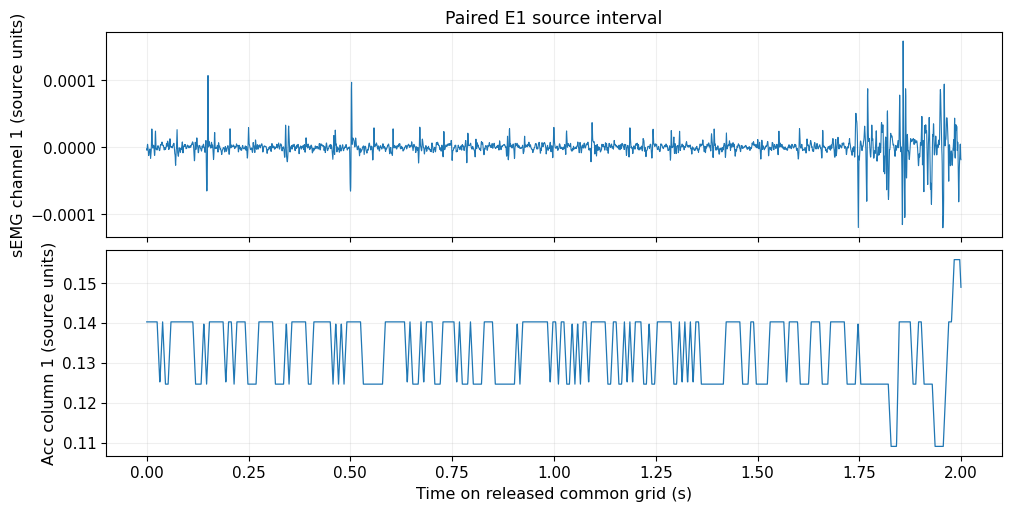

In [7]:
# =========== 06. Inspect Real Signal Quality and Temporal Context ============

quality = pd.DataFrame({
    "modality": ["sEMG", "Acceleration"],
    "channels": [record.emg.shape[1], record.acc.shape[1]],
    "finite_fraction": [np.isfinite(record.emg).mean(), np.isfinite(record.acc).mean()],
})
display(quality)
length = min(len(record.emg), int(RELEASED_RATE_HZ * 2))
t_s = np.arange(length) / RELEASED_RATE_HZ
fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True, layout="constrained")
axes[0].plot(t_s, record.emg[:length, 0], lw=0.8)
axes[0].set(ylabel="sEMG channel 1 (source units)", title="Paired E1 source interval")
axes[1].plot(t_s, record.acc[:length, 0], lw=0.9)
axes[1].set(xlabel="Time on released common grid (s)", ylabel="Acc column 1 (source units)")
for ax in axes: ax.grid(alpha=0.2)
save_figure(fig, output_dir / "01_alignment_examples.png")
plt.show()


**07. Export Source, Label and Sensor Dictionaries**

Export three complementary records rather than duplicating the original signal arrays:

- `01_pairing_registry.csv` identifies the inspected participant, exercise, source filename, sample count, channel dimensions and source-level data coverage.
- `01_label_dictionary.csv` contains the observed corrected E1 class codes, sample support and nominal duration for each class.
- `01_sensor_dictionary.csv` describes the **12 sEMG columns** and **36 acceleration columns** as twelve three-axis acceleration groups.

These small tables provide the explicit E1 source and class contract consumed by Notebook 02. Participant identifiers, labels and repetition codes are metadata for segmentation and evaluation; none enters the predictive input tensors.

In [8]:
# ============= 07. Export Source, Label and Sensor Dictionaries ==============

sensors = ([{"modality": "sEMG", "column": f"emg_{i+1:02d}",
             "sensor_module": i+1, "axis": "sEMG"} for i in range(12)]
           + [{"modality": "Acceleration", "column": f"acc_{i*3+j+1:02d}",
               "sensor_module": i+1, "axis": "xyz"[j]} for i in range(12) for j in range(3)])
sensor_dictionary = pd.DataFrame(sensors)
audit.to_csv(output_dir / "01_pairing_registry.csv", index=False)
label_dictionary.to_csv(output_dir / "01_label_dictionary.csv", index=False)
sensor_dictionary.to_csv(output_dir / "01_sensor_dictionary.csv", index=False)
display(sensor_dictionary.groupby("modality", as_index=False).agg(columns=("column", "count")))


,modality,columns
0,Acceleration,36
1,sEMG,12


**08. Source Evidence and Handover to Paired Windowing**

This notebook establishes that S01 E1 has consistent source-array lengths, finite paired recordings and a corrected label/repetition inventory. The recorded class set **0–17** and the source metadata support subsequent inspection of additional participants. A complete source-cohort inventory and participant-independent modelling cohort are constructed in Notebook 02, rather than inferred from this single participant.

The current named `01_*` tables and source trace are written to the study's `output/` directory. The downloaded archive remains in `data/raw/ninapro_db2/` for local reuse. Notebook 02 reads `01_label_dictionary.csv` and `01_pairing_registry.csv` directly, then processes participant archives to create its canonical paired-window indices and fold assignments.

In [9]:
# ============= 08. Current Outputs and Scientific Interpretation =============

display(pd.DataFrame({"output_file": [
    p.name for p in sorted(output_dir.glob("%02d_*" % NOTEBOOK_NUMBER))
    if p.is_file()
]}))
download_outputs_from_colab(
    folder="multimodal_movement_learning/output",
    stage=f"{NOTEBOOK_NUMBER:02d}",
)


,output_file
0,01_alignment_examples.png
1,01_label_dictionary.csv
2,01_pairing_registry.csv
3,01_sensor_dictionary.csv


------------------------------------------------------------------------
Notebook 01
Files packaged: 4
  + 01_alignment_examples.png
  + 01_label_dictionary.csv
  + 01_pairing_registry.csv
  + 01_sensor_dictionary.csv
Download ZIP from Colab Contents: /content/multimodal_movement_learning_Notebook_01_Outputs.zip
